# Consumer Financial Complaints Analysis
### INFO 4360 – Complex Data Analytics

**Team Members:** Rebecca Quaye and Ketty Odero  
**Project:** Consumer Complaint Classification Using Natural Language Processing (NLP)  
**Analysis Path:** Path A – Predictive Classification

---

## Project Overview

This project explores whether consumer complaint narratives can be used to predict the financial product category associated with a complaint.

We analyze a sample of 5,000 complaints from the Consumer Financial Protection Bureau (CFPB), covering 11 financial product categories between August 2025 and July 2026.

## Research Question

**Can consumer complaint narratives accurately predict the financial product category associated with a complaint?**

## Analysis Approach

Our analysis includes:

1. **Exploratory Data Analysis (EDA):** Examining product distributions, missing values, narrative lengths, and duplicate complaints.
2. **Text Preprocessing:** Cleaning complaint narratives and preparing text for analysis.
3. **Text Mining:** Exploring word frequencies, bigrams, TF-IDF, and product-specific vocabulary.
4. **Sentiment Analysis:** Comparing baseline VADER sentiment scores with an experimental domain-adjusted approach.
5. **Predictive Modeling (Planned):** Using TF-IDF with Logistic Regression, Naive Bayes, and Linear SVM to classify complaints.
6. **LLM Comparison (Planned):** Exploring Claude API classification and comparing its results with traditional machine learning models.

## Project Goal

Our goal is to understand patterns in consumer complaint narratives and investigate whether NLP can help organizations automatically categorize incoming complaints.

---

**Note:** The exploratory and text analyses are part of our Phase 2 development. Predictive modeling and LLM comparisons are planned for Phase 3.

## 0. Setup
### 0.1 Imports

In [1]:
# Show charts inside the notebook on the first run
%matplotlib inline

# Make the src/ folder importable
import sys
sys.path.append("..")   # also look one folder up for src/, in case the notebook runs from Notebook/

# Data handling
import re
from collections import Counter
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Text processing for the raw word counts in sections 2.2 and 2.3 (NLTK)
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download(["stopwords", "wordnet"], quiet=True)   # word lists needed by the cleaning step (skipped if already installed)

# Project helper functions (src/data_utils.py, src/preprocessing.py, src/text_analysis.py)
from src.data_utils import load_complaints, missing_values, duplicate_narratives, TEXT_COL
from src.preprocessing import (clean_text, drop_duplicate_narratives, top_terms,
                               distinctive_terms, product_word_matrix)
from src.text_analysis import (sentiment_scores, sentiment_label, positive_word_contributions,
                               FINANCE_WORDS)
from src.preprocessing import STOPWORDS

# Notebook themes: one consistent chart style for every figure
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95,
              rc={"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12})
MAIN = sns.color_palette("deep")[0]      # one colour for every single-series chart
ACCENT = sns.color_palette("deep")[3]    # used only to highlight a key value
pd.set_option("display.max_colwidth", 200)   # show up to 200 characters of text in tables

### 0.2 Load the data

In [2]:
# Load the complaint sample. load_complaints reads the CSV, parses the dates and adds
# three helper columns: month, product_short (short product names) and word_count
DATA_PATH = "./Data/cfpb_complaints_sample_2025-08_to_2026-07.csv"
df = load_complaints(DATA_PATH)

## 1. Data exploration

### 1.1 Size and structure

A quick look at how many complaints we have, the period they cover, and the columns we will use.
Note: the 19 columns include 3 helper columns created by `load_complaints` (`month`, `product_short`, `word_count`).

In [3]:
# Preview the first two rows with every column, to see what each field looks like
df.head(2)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID,month,product_short,word_count
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a pattern of payment re-aging, unapplied funds, and fabricated fees on my post-discharge mortgage account. Agents repeatedly invoked bankruptcy discla...",Company has responded to the consumer and the CFPB and chooses not to provide a public response,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019,2025-11,Mortgage,5058
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,"I am filing a complaint against Affirm regarding a consumer loan used to finance a purchase that was never full delivered. On XX/XX/year>, I entered into a financing agreement with Affirm to purch...",NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170,2026-04,Debt management,351


In [4]:
# --- Dataset size and scope ---
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")

# Date range covered by the sample (should run Aug 2025 to Jul 2026)
print(f"Complaints received: {df['Date received'].min():%b %d, %Y} to {df['Date received'].max():%b %d, %Y}")

# Number of target classes (products) and how many different companies appear
print(f"Product categories: {df['Product'].nunique()}   Companies: {df['Company'].nunique()}")

# --- Preview: first 5 complaints, showing the key columns only ---
df[["Date received", "product_short", "Issue", "word_count"]].head()

Rows: 5,000   Columns: 19
Complaints received: Aug 01, 2025 to Jul 29, 2026
Product categories: 11   Companies: 626


,Date received,product_short,Issue,word_count
0,2025-11-03,Mortgage,Trouble during payment process,5058
1,2026-04-27,Debt management,Didn't provide services promised,351
2,2026-05-19,Debt management,Confusing or misleading advertising or marketing,275
3,2025-11-29,Debt collection,False statements or representation,242
4,2026-02-09,Credit reporting,Incorrect information on your report,120


### 1.2 Missing values

In [5]:
# Count missing values per column (only columns with at least one gap are listed)
missing_values(df)

,missing_rows,share_missing
Tags,4182,0.836
Company public response,3436,0.687
Sub-issue,1398,0.280
State,38,0.008
ZIP code,10,0.002


The two columns we need, the narrative (input X) and the product (target Y), have **no missing values**, so all 5,000 complaints can be used and no rows are dropped. The gaps are in fields we will not use as model inputs: `Tags` (84% missing) is only filled for older Americans and servicemembers, and `Company public response` (69%) is optional. `Sub-issue` (28%) is blank for issues that have no sub-issues.

### 1.3 Target distribution: our sample vs. the full database

In the full CFPB database one category dominates. We sampled the same number of complaints per product so the model learns every category, not just credit reporting.

In [6]:
# Count complaints by product (the target variable we will predict)
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

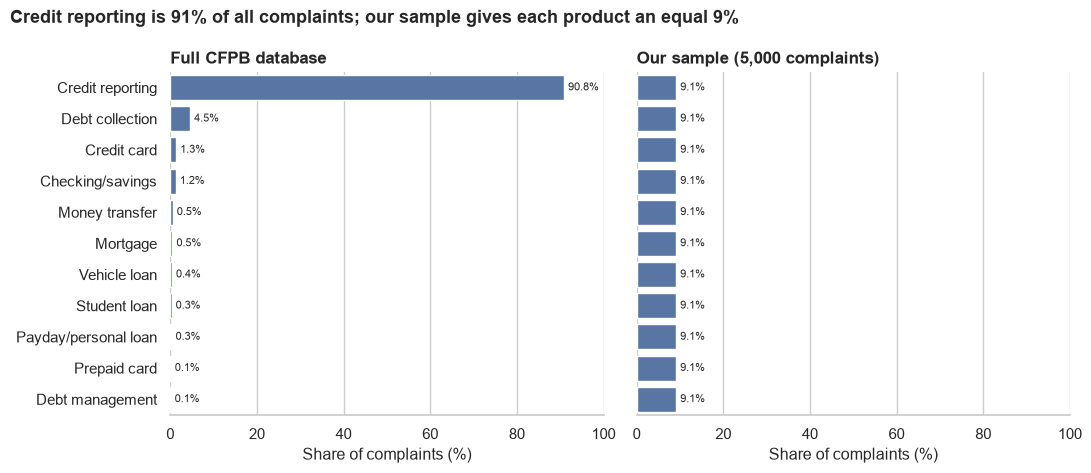

In [7]:
# Product counts shown on the CFPB complaint search page (all complaints, Oct 2026)
database_counts = pd.Series({
    "Credit reporting": 6_341_482, "Debt collection": 317_439, "Credit card": 92_750,
    "Checking/savings": 85_931, "Money transfer": 38_217, "Mortgage": 32_110,
    "Vehicle loan": 24_617, "Student loan": 19_519, "Payday/personal loan": 17_907,
    "Prepaid card": 6_122, "Debt management": 4_243,
})
# Convert counts to % shares so the full database and our sample can be compared on one scale
database_share = database_counts / database_counts.sum() * 100
sample_share = df["product_short"].value_counts(normalize=True) * 100

order = database_share.sort_values().index      # same product order in both panels

shares = pd.DataFrame({"Full CFPB database": database_share,
                       "Our sample (5,000 complaints)": sample_share}).reindex(order[::-1])

# Two side-by-side bar charts: full database (left) vs. our sample (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, column in zip(axes, shares.columns):
    sns.barplot(x=shares[column], y=shares.index, color=MAIN, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)   # write the % at the end of each bar
    ax.set(xlim=(0, 100), xlabel="Share of complaints (%)", ylabel="", title=column)

fig.suptitle("Credit reporting is 91% of all complaints; our sample gives each product an equal 9%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- Our sample is **balanced by design**: 454 or 455 complaints for each of the 11 products (table above).
- The real complaint stream is extremely imbalanced: credit reporting is about 91%, and the six smallest products are each under 0.5%. A model trained on raw data could score 91% accuracy by always guessing "credit reporting" and still be useless for routing.
- Because the sample is balanced, **accuracy is a fair headline metric**, and **macro F1** (which weights every product equally) shows whether small products are handled well.
- For Phase 3: a model trained on balanced data will over-predict small products when used on real traffic. We will note this and consider adjusting for real-world frequencies when interpreting results.

### 1.4 Coverage over time

In [8]:
# Number of complaints received in each month of the sample
per_month = df["month"].value_counts().sort_index()
print(per_month.to_string())

# Smallest count in the month x product table: if it is above 0, every product appears in every month
print(f"\nSmallest product-month cell: {pd.crosstab(df['month'], df['Product']).min().min()} complaints")

month
2025-08    418
2025-09    418
2025-10    418
2025-11    418
2025-12    418
2026-01    418
2026-02    418
2026-03    418
2026-04    418
2026-05    418
2026-06    413
2026-07    407
Freq: M

Smallest product-month cell: 37 complaints


- Every month from August 2025 to May 2026 has 418 complaints; June (413) and July (407) are slightly lower, likely because fewer recent narratives were published before the CFPB stopped publishing narratives in August 2026. Every product appears in every month (the smallest product-month count is 37), so no single month drives the patterns we find.

### 1.5 Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.

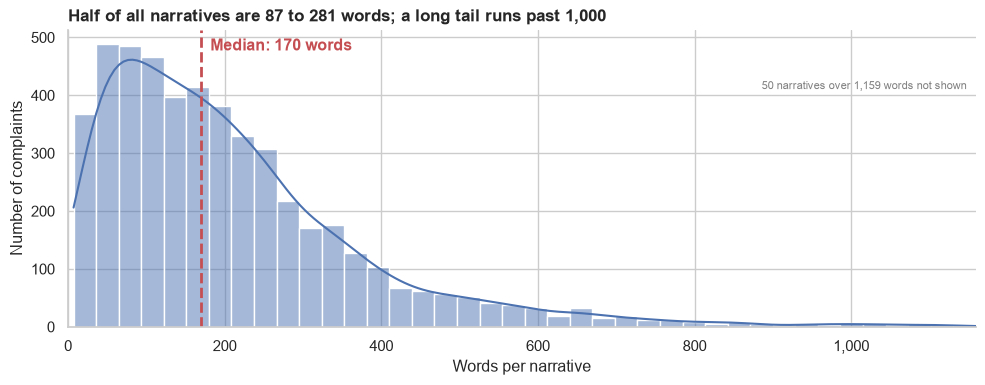

count    5000.0
mean      225.0
std       251.0
min         7.0
25%        87.0
50%       170.0
75%       281.0
max      5058.0
Under 50 words: 12%   Over 500 words: 7%


In [9]:
# Number of words in each narrative (helper column created by load_complaints)
words = df["word_count"]

# Plain (linear) axis: show the chart up to the 99th percentile so the long tail
# doesn't squash the bars; the statistics below still use every complaint
cap = words.quantile(0.99)
shown = words[words <= cap]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(shown, bins=40, color=MAIN, kde=True, ax=ax)   # bars = counts, line = smoothed shape
# Dashed line and label at the median
ax.axvline(words.median(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(words.median() + cap * 0.01, ax.get_ylim()[1] * 0.93, f"Median: {words.median():.0f} words",
        color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))   # 1,000 instead of 1000
ax.set(xlim=(0, cap), xlabel="Words per narrative", ylabel="Number of complaints",
       title="Half of all narratives are 87 to 281 words; a long tail runs past 1,000")
# Note on the chart how many long narratives fall outside the plotted range
ax.text(0.99, 0.80, f"{(words > cap).sum()} narratives over {cap:,.0f} words not shown",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
sns.despine()
plt.tight_layout()
plt.show()

# Summary statistics on ALL narratives, plus the share of very short and very long ones
print(words.describe().round(0).to_string())
print(f"Under 50 words: {(words < 50).mean():.0%}   Over 500 words: {(words > 500).mean():.0%}")

Complaint narrative lengths are right-skewed, with most complaints containing relatively short narratives and fewer complaints having very long narratives. The median narrative is 170 words, while the mean is higher at 225 words, and the longest runs to 5,058 words. This difference reflects a smaller number of very long complaints: 7% are over 500 words, while 12% are under 50 words.

For readability, the histogram displays narratives up to the 99th percentile. The full dataset, including longer narratives, is retained for the analysis. The variation in narrative length may be important when preprocessing the text and building the classification model.

### 1.6 Data quality: redactions and template letters

In [10]:
# Share of narratives containing CFPB redactions (two or more X's in a row, e.g. XXXX)
has_redaction = df[TEXT_COL].str.contains(r"X{2,}")
print(f"Narratives with redacted text (XXXX): {has_redaction.mean():.0%}")

# Narratives whose text appears more than once (template letters)
dupes = duplicate_narratives(df)
extra_copies = int((dupes["copies"] - 1).sum())   # copies beyond the first one of each letter
print(f"Narratives that appear more than once: {len(dupes)}  ({extra_copies} extra copies)")
dupes.head(5)   # the five most repeated letters

Narratives with redacted text (XXXX): 82%
Narratives that appear more than once: 44  (105 extra copies)


,copies,narrative_start
0,27,There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15...
1,13,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Repo..."
2,7,My rights were violated as a consumer under 15USC1681B and I need them blocked and deleted from my report ASAP...
3,7,I want to stress that I did not give written permission for these specific transactions to be included in my consumer re...
4,5,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to repor...


- **82% of narratives contain CFPB redactions** (`XXXX` for names, account numbers and dates). These are meaningless to a model, so the cleaning step will remove them before counting words.
- **105 rows are exact copies** of 44 template letters, mostly credit reporting disputes citing FCRA sections. If copies land in both the training and test sets, the model is tested on text it has already seen and its score is inflated. We remove the extra copies before modeling, leaving 4,895 unique narratives.

### 1.7 Example narratives (one per product)

In [11]:
# Display one sample complaint narrative per product (random_state fixes the sample so it is reproducible)
sample_complaints = (
    df[["Product", "Consumer complaint narrative"]]
    .groupby("Product")
    .sample(n=1, random_state=42)
    .sort_values("Product")
)

# Print the product and the first 500 characters of its narrative
for _, row in sample_complaints.iterrows():
    print("Product:", row["Product"])
    print("Narrative:", row["Consumer complaint narrative"][:500])
    print("-" * 80)

Product: Checking or savings account
Narrative: On XX/XX/year>2025, a teller at a Chase branch store stole {$1200.00} from my cash deposit while I was having a medical emergency. I am a type XXXX XXXX  and was experiencing XXXX XXXX XXXX  at the time, not feeling well. The teller noticed something was wrong, but instead of helping me, she took advantage of my condition and shorted my deposit. 

I tried filing a complaint with Chase immediately after the incident by calling the fraud department, and again on XX/XX/year>2025. Each time I was to
--------------------------------------------------------------------------------
Product: Credit card
Narrative: - I have been unable to log into my account for almost a year. Since XX/XX/XXXX. - I attempted to log in while on the phone with a Synchrony representative who confirmed that the information I was entering was correct, yet the system continued to reject it ; no technical ticket was opened and no remedy was provided to me outside of a re

The sample complaints vary in length and writing style, but they contain language that provides clues about the financial product involved. Some name the product outright ("my mortgage account", "private student loan", "my vehicle", "Amex giftcard"), while others only point to it through context, such as a company or service name (PayPal for money transfer, Cash App Borrow for a payday loan). The mortgage example is itself about credit reporting of a late payment, so a single complaint can touch more than one product.

This supports the use of text classification for categorizing unlabeled complaints, but it also highlights a potential concern: explicit product words may make some complaints easier to classify. We will examine this further in the modeling phase as part of our leakage and sanity checks.

## 2. Text mining

### 2.1 Preparing the text

Before counting words we (1) keep one copy of each duplicate narrative, so a template letter sent 27 times is not counted 27 times, and (2) clean each narrative with `clean_text` from `src/preprocessing.py`: lower-case, and remove CFPB redactions (`XXXX`), dollar amounts, numbers and punctuation.

For the simple word counts in 2.2 and 2.3 we use a second, stricter cleaning (`clean_for_counts`): lower-case, keep letters only, drop English stopwords and redaction placeholders, and lemmatize ("payments" → "payment"), so that counts group word forms together. These counts run on all 5,000 narratives.

In [12]:
# Remove duplicate template letters, then clean every narrative
text_df = drop_duplicate_narratives(df)                 # keep one copy of each template letter
text_df["clean"] = text_df[TEXT_COL].map(clean_text)   # cleaned text used for TF-IDF and sentiment checks
print(f"Unique narratives used for text mining: {len(text_df):,}")

# Before / after cleaning for one complaint
example = text_df.iloc[3]
print("\nBEFORE:", example[TEXT_COL][:300])
print("\nAFTER: ", example["clean"][:300])

Unique narratives used for text mining: 4,895

BEFORE: I am writing in response to your communication regarding the abovereferenced alleged debt. I dispute this debt in its entirety ( or, if applicable, I dispute the amount you claim is owed ) and request full validation under the Fair Debt Collection Practices Act ( FDCPA ), 15 U.S.C. 1692g.

Please pr

AFTER:  i am writing in response to your communication regarding the abovereferenced alleged debt i dispute this debt in its entirety or if applicable i dispute the amount you claim is owed and request full validation under the fair debt collection practices act fdcpa u s c g please provide in writing the n


In [13]:
# Stricter cleaning for raw word counts (stopwords removed, lemmatized)
stop_words = set(stopwords.words("english"))   # common English words such as "the", "and", "is"
lemmatizer = WordNetLemmatizer()               # reduces words to their base form ("payments" -> "payment")

def clean_for_counts(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Split text into individual words
    words = text.split()

    # Remove stopwords and redaction placeholders
    words = [
    word for word in words
    if word not in stop_words and not re.fullmatch(r"x+", word)
    ]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return " ".join(words)

# Apply stricter cleaning to unique narratives for word-frequency analysis
text_df["clean_narrative"] = text_df[TEXT_COL].apply(clean_for_counts)


### 2.2 Most common words and phrases across all complaints

We start with single words, then move to two-word phrases (bigrams), which carry more meaning.

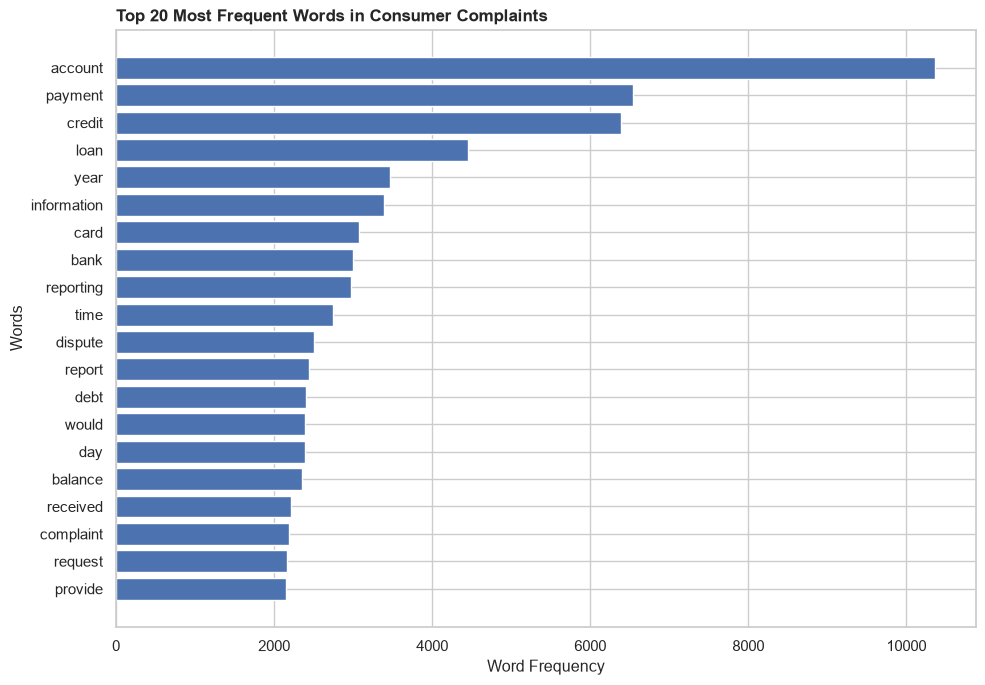

In [14]:
# Count the most common single words across all narratives

# Combine cleaned words from unique complaint narratives
all_words = " ".join(text_df["clean_narrative"]).split()
# Count how often each word appears
word_counts = Counter(all_words)   # Counter maps each word to the number of times it appears

# Get the 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)
# Plot the 20 most frequent words
plt.figure(figsize=(10, 7))

plt.barh(top_words["Word"], top_words["Frequency"])

plt.title("Top 20 Most Frequent Words in Consumer Complaints")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

# Display the most frequent word at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Interpretation

- **Account** is the most frequently used word, followed by **payment**, **credit**, and **loan**. These terms reflect common financial issues discussed in consumer complaints.
- Most of the frequently occurring words are general financial terms that appear across different product categories.
- Although individual words help us understand the main topics in complaints, they may not be enough to distinguish financial products. This is why we also examine bigrams and other text-mining techniques.

**Note:** This analysis uses 4,895 unique complaint narratives after removing duplicates to avoid counting repeated text multiple times.

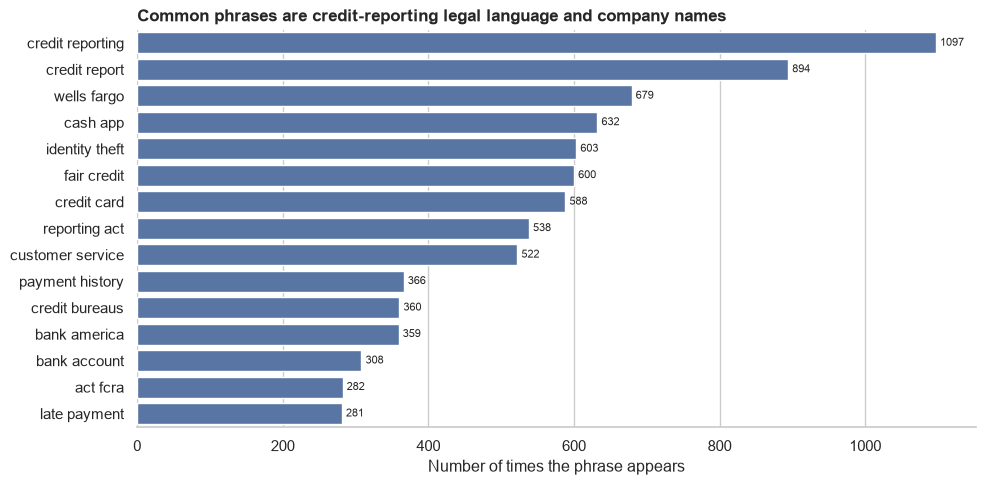

In [15]:
# Top 15 two-word phrases across all complaints
top_phrases = top_terms(text_df["clean"], n=15, ngram_range=(2, 2))   # ngram_range=(2, 2): two-word phrases only

# Horizontal bar chart, most frequent phrase at the top
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_phrases, x="count", y="term", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)   # write the count at the end of each bar
ax.set(xlabel="Number of times the phrase appears", ylabel="",
       title="Common phrases are credit-reporting legal language and company names")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- The two most frequent phrases are "credit reporting" (1,097) and "credit report" (894), and several others ("fair credit", "reporting act", "act fcra") come from **legal language about the Fair Credit Reporting Act**. Consumers in several products, not only credit reporting, quote this law, so these phrases alone will not separate products cleanly.
- **Company names** are among the most common phrases: "wells fargo" (679) and "cash app" (632) rank third and fourth, and "bank america" (359) also appears. A company usually points to a product (Cash App means money transfer), so the model may lean on them. That is useful for routing at one bank, but we will check in Phase 3 that the model is not relying on company names alone.
- "Identity theft" (603 mentions) is a major theme on its own.

### 2.3 The words that distinguish each product

**Raw counts first.** The most frequent words within each product:

In [16]:
# Get the most common words for a product category
def get_top_words_by_product(product, n=10):

    # Select cleaned narratives for the chosen product
    product_text = text_df.loc[
        text_df["Product"] == product, "clean_narrative"
    ]

    # Combine the narratives into individual words
    words = " ".join(product_text).split()

    # Count the words
    word_counts = Counter(words)

    # Return the most frequent words
    return pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )


# Get the top 5 words for each product category
product_word_summary = []

# Loop through all 11 financial product categories
for product in text_df["Product"].unique():

    top_words_product = get_top_words_by_product(product, n=5)

    product_word_summary.append({
        "Product": product,
        "Top 5 Words": ", ".join(top_words_product["Word"])
    })

# Display the summary
product_word_summary = pd.DataFrame(product_word_summary)

product_word_summary

,Product,Top 5 Words
0,Mortgage,"payment, mortgage, loan, account, year"
1,Debt or credit management,"account, credit, debt, payment, fee"
2,Debt collection,"account, debt, credit, reporting, collection"
3,Credit reporting or other personal consumer reports,"account, credit, reporting, information, report"
4,Credit card,"credit, account, card, payment, charge"
5,"Money transfer, virtual currency, or money service","account, transaction, fund, bank, app"
6,"Payday loan, title loan, personal loan, or advance loan","loan, payment, account, credit, year"
7,Vehicle loan or lease,"payment, vehicle, account, loan, credit"
8,Prepaid card,"card, account, transaction, fund, dispute"
9,Checking or savings account,"account, bank, fund, transaction, year"


Raw counts are dominated by words that are common everywhere: "account" is in the top 5 for all 11 products and "credit" for 7. A few product words do break through (*mortgage*, *vehicle*, *mohela*, *collection*, *app*), and mortgage complaints name their product directly, which supports the masking test planned for Phase 3.

**TF-IDF scores** fix this: they reward words that are frequent in a complaint but rare across all complaints, so the top TF-IDF words for each product are the ones that mark it out. These are the same features our Phase 3 classifier will use. Longer bars mean more distinctive words (bar lengths compare words within a product, not across products).

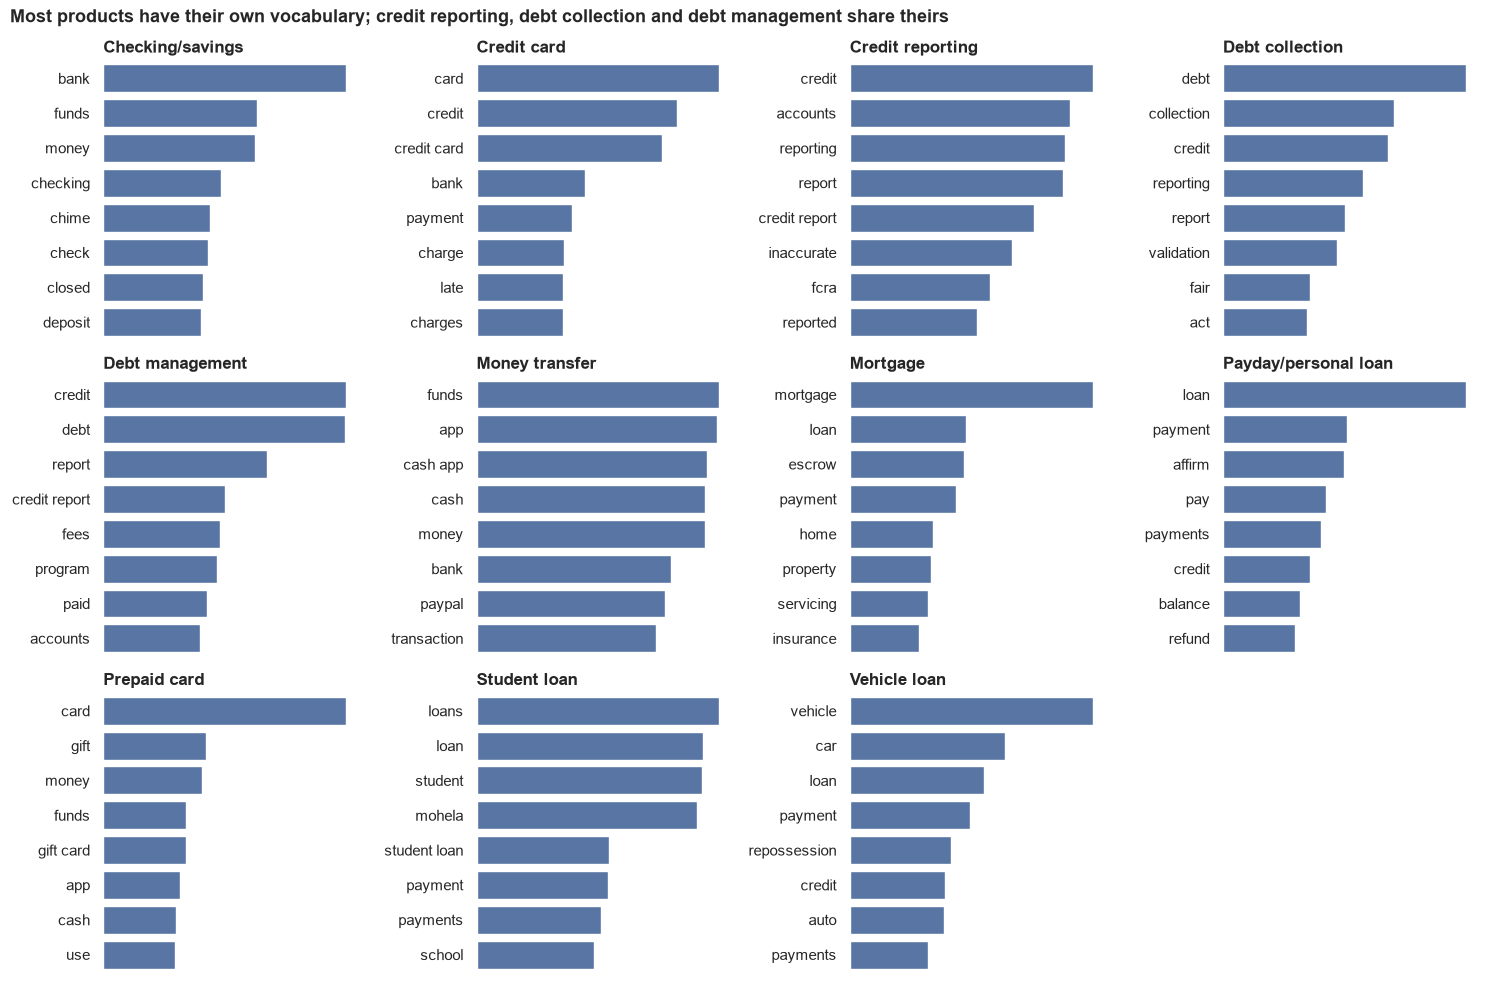

In [17]:
# Top 8 distinctive terms per product (highest average TF-IDF score)
distinct = distinctive_terms(text_df["clean"], text_df["product_short"], n=8)

# One small bar chart per product, arranged in a 3 x 4 grid
products = sorted(distinct["product"].unique())
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, product in zip(axes.flat, products):
    terms = distinct[distinct["product"] == product]   # this product's 8 terms
    sns.barplot(data=terms, x="score", y="term", color=MAIN, ax=ax)
    ax.set(title=product, xlabel="", ylabel="", xticks=[])   # scores only compare words within a product, so no x-axis
    sns.despine(ax=ax, left=True, bottom=True)
axes.flat[-1].axis("off")    # 11 products in a 12-slot grid: hide the empty one

fig.suptitle("Most products have their own vocabulary; credit reporting, debt collection and debt management share theirs",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

- **Eight products have clear, product-specific vocabulary:** mortgage (*escrow, property, servicing*), student loan (*school, mohela*), vehicle loan (*repossession, auto*), checking/savings (*deposit, check*), prepaid card (*gift card*). These should be easy to classify.
- **Credit reporting, debt collection and debt management share their top words** (*credit*, *report*). Debt management complaints are often about credit repair companies promising to fix a credit report, so their language overlaps with credit reporting. These categories share similar vocabulary, so we will examine whether the classification models confuse them more frequently in Phase 3.
- Company names show up as distinctive terms (*chime, mohela, affirm, paypal*). This confirms the point from 2.2: part of the signal is *who* the complaint is about, not just *what* it is about.

### 2.4 Word clouds: overlapping vs. distinct vocabulary

Word size shows how distinctive a word is for that product (TF-IDF). The three overlapping products sit beside mortgage, which has its own vocabulary.

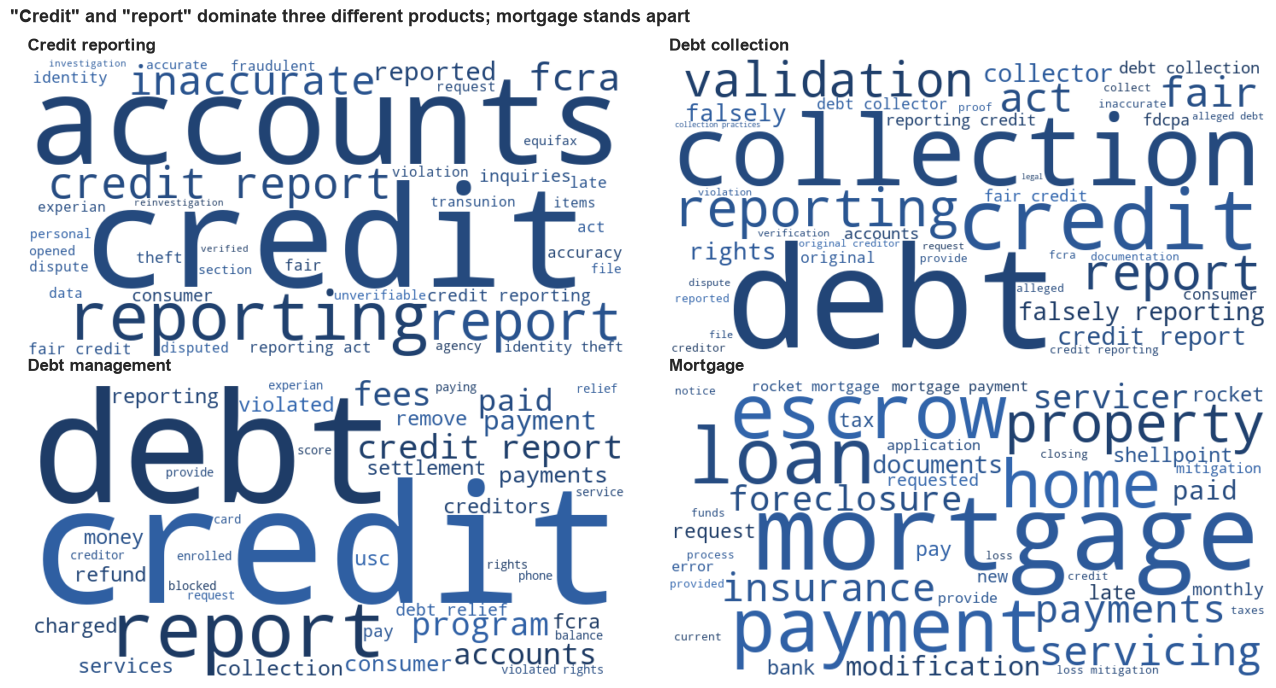

In [18]:
# Word clouds for the three overlapping products and one distinct product
cloud_products = ["Credit reporting", "Debt collection", "Debt management", "Mortgage"]
cloud_terms = distinctive_terms(text_df["clean"], text_df["product_short"], n=40)   # top 40 TF-IDF terms per product

def dark_blue(*args, **kwargs):
    # Colour every word in a readable dark blue (shades vary for texture)
    return f"hsl(215, 55%, {np.random.randint(25, 45)}%)"

# Draw one cloud per product in a 2 x 2 grid; word size = TF-IDF score
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, product in zip(axes.flat, cloud_products):
    weights = cloud_terms[cloud_terms["product"] == product].set_index("term")["score"].to_dict()   # {word: score}
    cloud = WordCloud(width=700, height=350, background_color="white", color_func=dark_blue,
                      prefer_horizontal=1.0, random_state=1).generate_from_frequencies(weights)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(product)
    ax.axis("off")   # hide the axes around the image

fig.suptitle('"Credit" and "report" dominate three different products; mortgage stands apart',
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The first three clouds are dominated by the same words (*credit, report, reporting, debt*), while the mortgage cloud shares almost none of them. For the routing team this means a complaint that talks about a credit report could belong to any of three teams; the deciding clues are smaller words such as *validation* (debt collection) or *program, fees* (debt management).

### 2.5 Vocabulary Overlap Across Financial Products (Jaccard Similarity)

We use Jaccard similarity to measure how much vocabulary is shared between financial product categories.

Jaccard similarity compares the number of shared words with the total number of unique words across two sets.

A score of 0 indicates no shared words, while a score of 1 indicates identical word sets.

This analysis helps us identify product categories with similar vocabulary and explore which categories might be more difficult to distinguish during predictive modeling.

In [19]:
# Get the 50 most common meaningful words for each financial product
top_words_by_product = {}

for product, group in text_df.groupby("Product"):

    # Combine the cleaned narratives and remove stopwords
    words = " ".join(group["clean"]).split()
    words = [word for word in words if word not in STOPWORDS]

    # Select the 50 most frequent words for each product
    word_counts = Counter(words)
    top_words_by_product[product] = set(
        word for word, count in word_counts.most_common(50)
    )

# Calculate Jaccard similarity between each pair of products
products = list(top_words_by_product.keys())

jaccard_matrix = pd.DataFrame(
    index=products,
    columns=products,
    dtype=float
)

for product_a in products:
    for product_b in products:
        words_a = top_words_by_product[product_a]
        words_b = top_words_by_product[product_b]

        # Count shared words and total unique words
        shared_words = len(words_a.intersection(words_b))
        total_unique_words = len(words_a.union(words_b))

        # Calculate Jaccard similarity
        jaccard_matrix.loc[product_a, product_b] = (
            shared_words / total_unique_words if total_unique_words else 0
        )

# Display the similarity scores
display(jaccard_matrix.round(2))

,Checking or savings account,Credit card,Credit reporting or other personal consumer reports,Debt collection,Debt or credit management,"Money transfer, virtual currency, or money service",Mortgage,"Payday loan, title loan, personal loan, or advance loan",Prepaid card,Student loan,Vehicle loan or lease
Checking or savings account,1.00,0.37,0.16,0.16,0.25,0.54,0.20,0.27,0.47,0.16,0.20
Credit card,0.37,1.00,0.19,0.22,0.39,0.32,0.25,0.45,0.32,0.25,0.35
Credit reporting or other personal consumer reports,0.16,0.19,1.00,0.47,0.27,0.10,0.11,0.20,0.09,0.16,0.23
Debt collection,0.16,0.22,0.47,1.00,0.37,0.14,0.16,0.32,0.12,0.20,0.33
Debt or credit management,0.25,0.39,0.27,0.37,1.00,0.23,0.28,0.45,0.20,0.33,0.39
"Money transfer, virtual currency, or money service",0.54,0.32,0.10,0.14,0.23,1.00,0.19,0.27,0.54,0.18,0.19
Mortgage,0.20,0.25,0.11,0.16,0.28,0.19,1.00,0.32,0.18,0.28,0.35
"Payday loan, title loan, personal loan, or advance loan",0.27,0.45,0.20,0.32,0.45,0.27,0.32,1.00,0.25,0.32,0.54
Prepaid card,0.47,0.32,0.09,0.12,0.20,0.54,0.18,0.25,1.00,0.14,0.16
Student loan,0.16,0.25,0.16,0.20,0.33,0.18,0.28,0.32,0.14,1.00,0.28


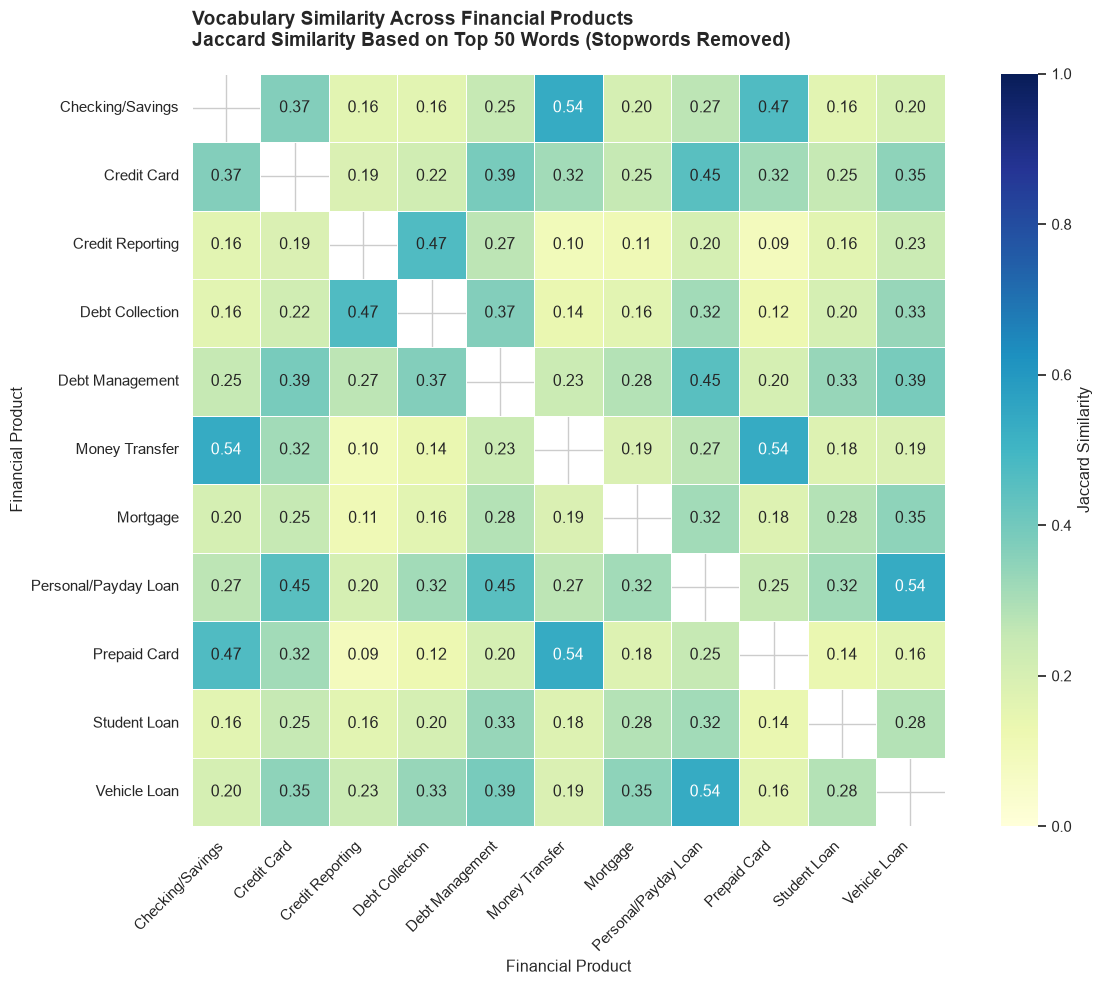

In [20]:
# Shorten product names to make the heatmap easier to read
short_names = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt Management",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Personal/Payday Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

# Apply shorter labels without changing the similarity scores
plot_matrix = jaccard_matrix.rename(
    index=short_names,
    columns=short_names
)

# Hide self-comparisons along the diagonal
mask = np.eye(len(plot_matrix), dtype=bool)

plt.figure(figsize=(13, 10))

sns.heatmap(
    plot_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Jaccard Similarity"}
)

plt.title(
    "Vocabulary Similarity Across Financial Products\n"
    "Jaccard Similarity Based on Top 50 Words (Stopwords Removed)",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Financial Product")
plt.ylabel("Financial Product")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation: Vocabulary Similarity Across Financial Products

The Jaccard similarity analysis compares the 50 most frequent words in each financial product category after removing stopwords.

- **Highest similarity (0.54):** Checking/Savings and Money Transfer, Money Transfer and Prepaid Card, and Personal/Payday Loan and Vehicle Loan share the most vocabulary. This makes sense because these products involve related financial activities.

- **Lowest similarity (0.09):** Credit Reporting and Prepaid Card have the least vocabulary overlap, suggesting that consumers use different language when describing problems with these products.

- **Credit Reporting and Debt Collection (0.47):** These categories share several common terms, which may make them harder for classification models to distinguish.

Overall, the results show that some financial products have distinct vocabularies, while others share similar language. This overlap may help explain potential classification errors when we evaluate our models in Phase 3.

### 2.6 Do complaints name their own product?

If most complaints simply say "my mortgage" or "my student loan", classification is easy but partly trivial. The chart shows, for complaints of each product (rows), the share that mention the key words of each product (columns). Numbers on the outlined diagonal mean complaints name their own product; strong numbers off the diagonal mean they mention another product's words.

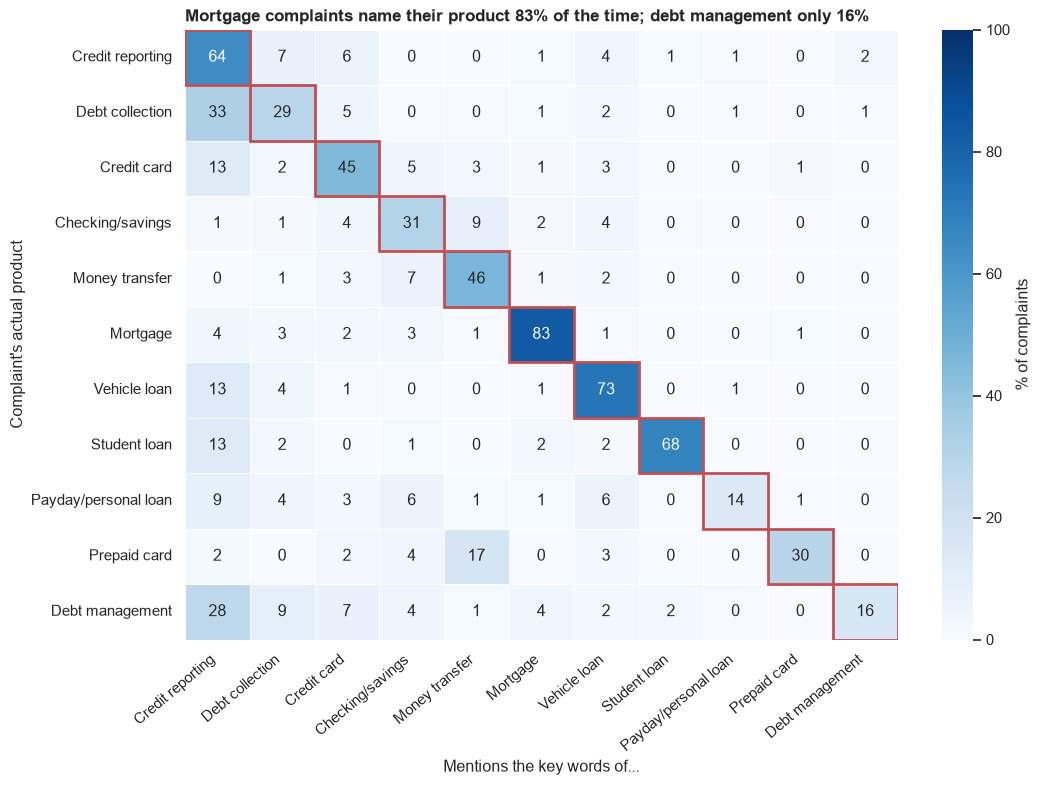

In [21]:
# % of complaints in each product (rows) that mention each product's key words (columns)
mentions = product_word_matrix(text_df)

# Heatmap: rows = actual product, columns = product whose key words are mentioned, cell = % of complaints
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mentions, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% of complaints"}, ax=ax)
ax.set(xlabel="Mentions the key words of...", ylabel="Complaint's actual product",
       title="Mortgage complaints name their product 83% of the time; debt management only 16%")

# Outline the diagonal: complaints mentioning their own product's words
for i in range(len(mentions)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2))
plt.xticks(rotation=40, ha="right")   # tilt column names so they do not overlap
plt.tight_layout()
plt.show()

- **Some products almost always name themselves:** mortgage (83%), vehicle loan (73%), student loan (68%) and credit reporting (64%). For these, a model can score well just by spotting the product word, which is why Phase 3 will **re-test the model with these words masked** to see how much accuracy depends on them.
- **Others rarely do:** only 14% of payday/personal loan and 16% of debt management complaints use their own product's words. These classes depend on indirect clues and will likely be harder.
- **The key off-diagonal finding:** 33% of debt collection complaints and 28% of debt management complaints use credit-reporting words, as much as or more than their own. This matches 2.3 and 2.4: credit reporting, debt collection and debt management are the classes we expect the model to confuse, and the cases where the routing team would most benefit from a second look.

### 2.7 Sentiment Analysis Using VADER

We use VADER sentiment analysis to examine the emotional tone of consumer complaint narratives. VADER assigns sentiment scores based on the words and expressions in a text.

This analysis will help us understand the overall sentiment of complaints and compare sentiment across financial product categories.

In [22]:
# Baseline VADER score for every complaint
text_df["sentiment_raw"] = sentiment_scores(text_df[TEXT_COL])            # compound score from -1 to +1
text_df["label_raw"] = sentiment_label(text_df["sentiment_raw"])          # Negative < -0.05 <= Neutral <= 0.05 < Positive

# Share of complaints in each sentiment label
print("Share of complaints by sentiment label (baseline VADER):")
print((text_df["label_raw"].value_counts(normalize=True) * 100).round(1).to_string())

Share of complaints by sentiment label (baseline VADER):
label_raw
Negative    60.1
Positive    36.0
Neutral      3.9


- VADER calls about **36% of complaints positive**, even though every narrative here is a complaint. To find out why, we add up which positive dictionary words contribute most across all complaints.

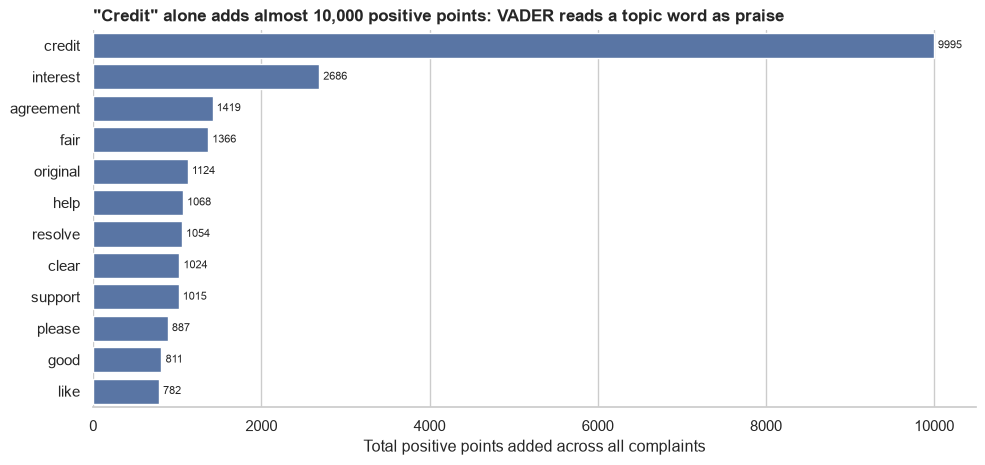

In [23]:
# Positive dictionary words that add the most to VADER scores
contributions = positive_word_contributions(text_df["clean"], n=12)   # top 12 words by total positive score added

# Horizontal bar chart of those words
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=contributions, x="positive_points", y="word", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)
ax.set(xlabel="Total positive points added across all complaints", ylabel="",
       title='"Credit" alone adds almost 10,000 positive points: VADER reads a topic word as praise')
sns.despine(left=True)
plt.tight_layout()
plt.show()

- VADER was built for social media, where *credit* means praise ("give credit") and *interest* means curiosity. In financial complaints these are **topic words**: *credit report*, *interest rate*, the **Fair** Credit Reporting Act, a loan **agreement**, even **Wells** Fargo. They inflate scores, most of all for credit-related products.

**Domain-adjusted sentiment analysis:** We make selected financial terms neutral in VADER's dictionary (`FINANCE_WORDS` in `src/text_analysis.py`) and calculate sentiment scores again. This is an experimental adjustment to reduce the influence of financial terminology, not a guaranteed improvement in sentiment accuracy.


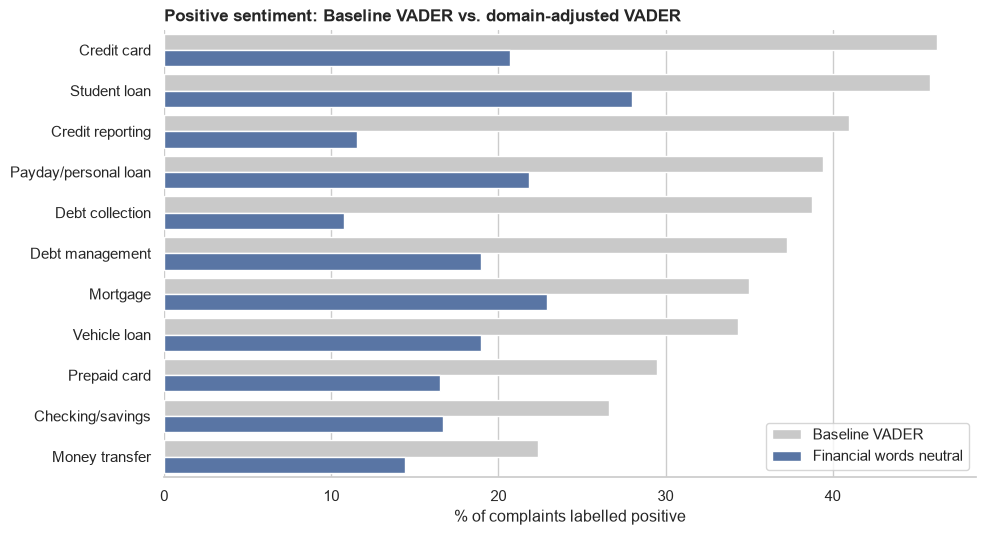

Overall share labelled positive: baseline 36%, domain-adjusted 18%


In [24]:
# Re-score with financial topic words made neutral
text_df["sentiment"] = sentiment_scores(text_df[TEXT_COL], neutral_words=FINANCE_WORDS)   # FINANCE_WORDS scored as 0
text_df["label"] = sentiment_label(text_df["sentiment"])

# Compare positive sentiment percentages before and after domain adjustment
positive_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
    "Financial words neutral": text_df["label"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
}).sort_values("Baseline VADER", ascending=False)

# Reshape to long format (one row per product and version) so seaborn can draw paired bars
plot_data = positive_share.reset_index().melt(id_vars="product_short", var_name="version",
                                              value_name="pct_positive")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="pct_positive", y="product_short", hue="version",
            palette=["#c9c9c9", MAIN], ax=ax)
ax.set(xlabel="% of complaints labelled positive", ylabel="",
       title="Positive sentiment: Baseline VADER vs. domain-adjusted VADER")
ax.legend(title="", loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Compare the overall share of positive sentiment before and after domain adjustment
print("Overall share labelled positive:",
      f"baseline {text_df['label_raw'].eq('Positive').mean():.0%},",
      f"domain-adjusted {text_df['label'].eq('Positive').mean():.0%}")


- After making selected financial terms neutral, VADER classified approximately **77% of complaints as negative**, compared with the baseline results.
- The percentage classified as positive decreased, especially for credit reporting, debt collection, and credit card complaints.
- About **18% of complaints still received positive sentiment labels**. Words such as *help*, *resolve*, *support*, and *please* may contribute to these scores even when consumers are describing problems.
- **Takeaway:** Domain-specific terminology can influence sentiment scores. However, this adjustment is experimental, and we would need manually labeled sentiment data to determine whether it improves accuracy.


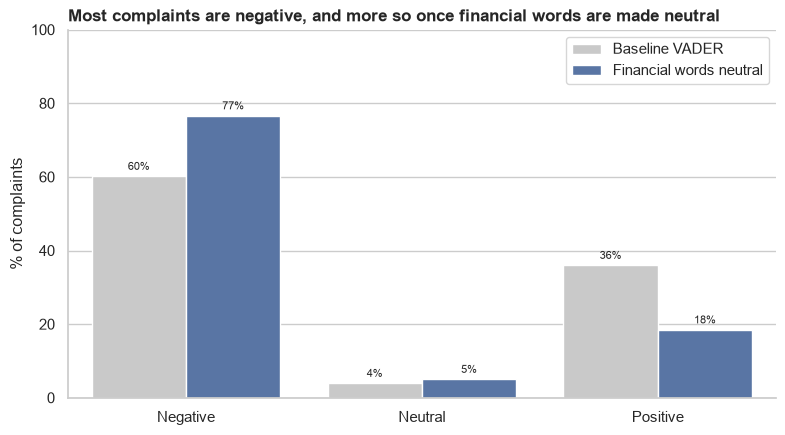

          Baseline VADER  Financial words neutral
Negative            60.1                     76.6
Neutral              3.9                      5.0
Positive            36.0                     18.4


In [25]:
# Share of complaints by sentiment label: baseline VADER vs. financial words neutral
order = ["Negative", "Neutral", "Positive"]   # fixed order for the x-axis
label_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].value_counts(normalize=True) * 100,
    "Financial words neutral": text_df["label"].value_counts(normalize=True) * 100,
}).reindex(order)

# Reshape to long format (one row per label and version) for paired bars
plot_data = label_share.reset_index(names="sentiment").melt(id_vars="sentiment", var_name="version",
                                                            value_name="pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_data, x="sentiment", y="pct", hue="version", order=order,
            palette=["#c9c9c9", MAIN], ax=ax)
for container in ax.containers:   # write the % above every bar
    ax.bar_label(container, fmt="%.0f%%", padding=3, fontsize=8)
ax.set(xlabel="", ylabel="% of complaints", ylim=(0, 100),
       title="Most complaints are negative, and more so once financial words are made neutral")
ax.legend(title="", loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

print(label_share.round(1).to_string())

- With baseline VADER, **60% of complaints are negative, 36% positive and 4% neutral**. Since every narrative is a complaint, a positive share this high is a warning sign.
- After financial topic words (*credit*, *interest*, *fair*, *agreement*) are made neutral, **77% of complaints are negative and 18% positive**. Almost all of the change moves from positive to negative; the neutral share stays small (4% to 5%).

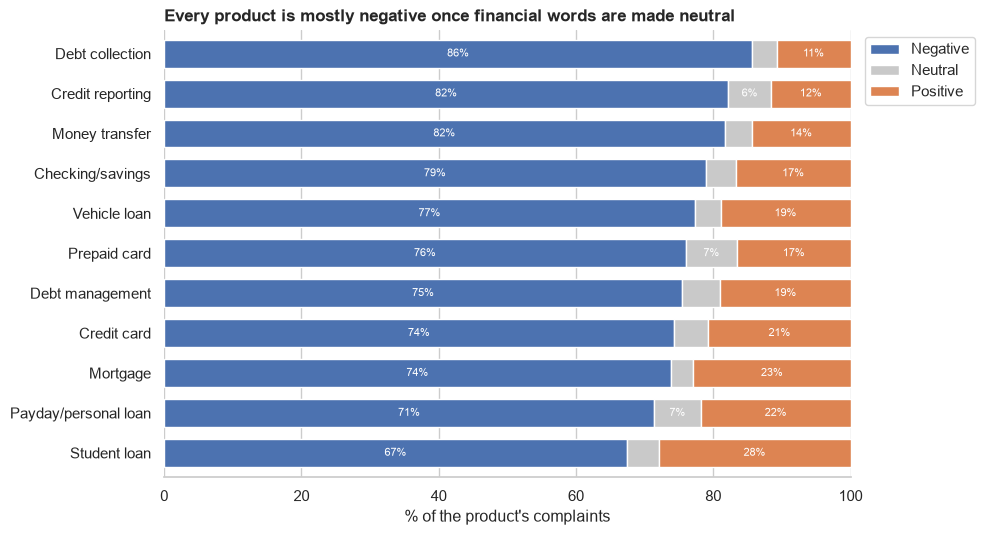

label                 Negative  Neutral  Positive
product_short                                    
Debt collection           85.6      3.6      10.8
Credit reporting          82.2      6.3      11.6
Money transfer            81.6      4.0      14.4
Checking/savings          78.9      4.4      16.7
Vehicle loan              77.3      3.7      18.9
Prepaid card              76.0      7.5      16.5
Debt management           75.4      5.6      19.0
Credit card               74.2      5.1      20.7
Mortgage                  73.8      3.3      22.9
Payday/personal loan      71.4      6.8      21.8
Student loan              67.4      4.6      28.0


In [26]:
# Negative / neutral / positive mix for each product (financial words neutral)
# % of each product's complaints in each label (each row adds up to 100)
sentiment_by_product = (pd.crosstab(text_df["product_short"], text_df["label"], normalize="index") * 100)
sentiment_by_product = sentiment_by_product[["Negative", "Neutral", "Positive"]].sort_values("Negative")

# One stacked bar per product: negative + neutral + positive = 100%
ax = sentiment_by_product.plot(kind="barh", stacked=True, figsize=(10, 5.5), width=0.7,
                               color=["#4c72b0", "#c9c9c9", "#dd8452"])
# Label each segment with its %, skipping segments under 6% that are too narrow to read
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color="white")
ax.set(xlim=(0, 100), xlabel="% of the product's complaints", ylabel="",
       title="Every product is mostly negative once financial words are made neutral")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(sentiment_by_product.round(1).sort_values("Negative", ascending=False).to_string())

- **Every product is mostly negative** once financial words are made neutral. Debt collection has the highest negative share (86%) and student loan the lowest (67%, with the highest positive share at 28%).
- Debt collection and credit reporting have some of the highest negative sentiment percentages after the domain adjustment. Their positive sentiment percentages decreased substantially, suggesting that financial terminology influenced the original VADER scores. However, we cannot confirm that the original positive labels were incorrect without manually reviewing and labeling the complaints.

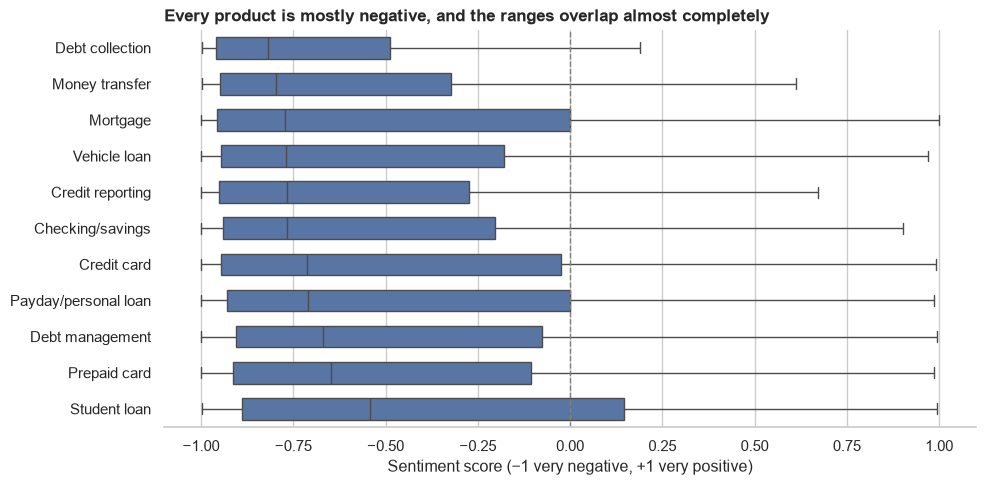

                              median  count
Company response to consumer               
Closed with explanation        -0.74   3971
Other                          -0.36    201
Relief given                   -0.75    723


In [27]:
# Does sentiment differ by product? (adjusted scores)
# Products ordered from most negative to least negative median score
order_by_sentiment = text_df.groupby("product_short")["sentiment"].median().sort_values().index

# Box = middle half of scores, line = median, whiskers = typical range (outliers hidden)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=text_df, x="sentiment", y="product_short", order=order_by_sentiment,
            color=MAIN, showfliers=False, width=0.6, ax=ax)
ax.axvline(0, color="grey", linewidth=1, linestyle="--")   # neutral line
ax.set(xlabel="Sentiment score (−1 very negative, +1 very positive)", ylabel="",
       title="Every product is mostly negative, and the ranges overlap almost completely")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Does sentiment differ by how the company responded?
# Group company responses into three outcomes, then compare median sentiment and counts
outcome = text_df["Company response to consumer"].map(
    lambda r: "Relief given" if "relief" in r else ("Closed with explanation" if "explanation" in r else "Other"))
print(text_df.groupby(outcome)["sentiment"].agg(["median", "count"]).round(2))

- Median sentiment ranges only from about −0.8 (debt collection, money transfer) to −0.5 (student loan), and the boxes overlap heavily. **Sentiment will not help the model tell products apart**, so we will not use it as a classification feature in Phase 3.
- Sentiment is also the same whether the company gave relief or just closed with an explanation (both about −0.75). So for our stretch question, *how angry* a consumer sounds does not predict *whether they get relief*.
- Where sentiment could still help is in **prioritising** within a team's queue (the most negative complaints first). If we need a reliable severity or urgency score, Claude can judge it from context, which a word list cannot. We will test that in our Phase 3 plan.

### 2.8 Summary: what Phase 2 means for Phase 3

| Finding | Evidence | Phase 3 action |
|---|---|---|
| Balanced sample (454–455 per product); real complaints are 91% credit reporting | 1.3 | Report accuracy and macro F1; note that a balanced model over-predicts small products on real traffic |
| 105 exact copies of 44 template letters | 1.6 | Remove copies before the train/test split (4,895 narratives) |
| Most products have their own vocabulary | 2.3, 2.4 | TF-IDF features with logistic regression as the baseline |
| Credit reporting, debt collection and debt management share vocabulary | 2.3–2.5 | Per-class precision and recall, and a confusion matrix |
| Many complaints name their own product (mortgage 83%) | 2.6 | Re-train with product words masked and compare macro F1 |
| Company names are among the most common and distinctive terms | 2.2, 2.3 | Inspect top features; test a version with company names removed |
| Sentiment is mostly negative for every product and overlaps across products | 2.7 | Do not use sentiment as a classification feature |

## 3. Phase 3 Plan

**Goal.** Predict the **Product** (11 categories, Y) from the **Consumer complaint narrative** (X). The intended use is routing complaints that arrive without a product label, such as emails, chat messages or call transcripts, to the right team.

**Models.** Narratives are converted to TF-IDF features (unigrams and bigrams) and split 70% training / 30% testing, stratified by product. Logistic Regression is the baseline, compared with Multinomial Naive Bayes and Linear SVM. Evaluation and sanity checks follow the table in 2.8.

**Claude API (small sample).**
- **Prediction comparison:** ask Claude to assign each complaint to one of the same 11 categories, and compare with the true labels and the model predictions.
- **Error analysis:** ask Claude which words or context led to selected misclassifications.
- **Severity scoring:** rate how serious each complaint is from context, which VADER cannot do (2.7), to help prioritise a team's queue.

Example prompt: *"Read the following consumer financial complaint and identify the most appropriate financial product category from the 11 categories provided. Return only the selected category and a brief explanation based on the complaint narrative."*

Narratives will be checked for sensitive information before they are sent, the sample will be kept small to control cost, the prompt and model settings will be fixed for consistency, and Claude's output will be treated as exploratory rather than as ground truth. Claude supports the classifiers; it does not replace them.

## 4. Phase 2 Progress Update

**Completed.** We explored 5,000 CFPB complaints (August 2025 to July 2026, 11 products): structure, missing values, product balance, coverage over time, narrative length, redactions and duplicates. We then cleaned the text and ran word and phrase frequencies, TF-IDF distinctive terms, word clouds, a product-word mention check and VADER sentiment analysis with an experimental adjustment for financial terminology. Topic modeling was left out of this phase. The key findings are summarised in 2.8.

**Next.** Build and evaluate the three classifiers, run the masking and company-name checks, and carry out the Claude API comparison, error analysis and severity scoring described in section 3.